# From Data to Forecasts: Modern Time-Series Forecasting with Deep Learning
DevFest Sherbrooke 2026 · full, reproducible notebook

**Task:** every day at midnight, forecast Ontario's hourly electricity demand for the next 24 hours.

**Models compared on 2026 data:** seasonal baselines, a linear Keras model, an LSTM, a quantile LSTM (P10/P50/P90) and TimesFM (zero-shot).

**Run:** `Runtime → Change runtime type → T4 GPU`, then `Runtime → Run all`.

**Data:** [IESO hourly Ontario demand](https://www.ieso.ca/power-data/data-directory), MW.

## Setup

In [ ]:
import io, os, warnings, requests
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras

warnings.filterwarnings("ignore")
SEED = 42
keras.utils.set_random_seed(SEED)

C = dict(actual="#1e1e1e", naive="#9aa0a6", seasonal="#fbbc04", linear="#34a853",
         lstm="#4285f4", qlstm="#ea4335", timesfm="#a142f4", band="#c3ecf6")
plt.rcParams.update({"figure.figsize": (12, 4), "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "font.size": 12, "axes.titleweight": "bold"})
for d in ["figures", "models", "artifacts"]:
    os.makedirs(d, exist_ok=True)

def save(fig, name):
    fig.savefig(f"figures/{name}.png", dpi=200, bbox_inches="tight", facecolor="white")

print("TensorFlow", tf.__version__, "| GPU:", tf.config.list_physical_devices("GPU") or "none")

TensorFlow 2.21.0 | GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 1 · Data

In [ ]:
YEARS = range(2020, 2027)
CACHE = "artifacts/ontario_demand.csv"
BACKUP_CSV_URL = ""  # raw GitHub URL of artifacts/ontario_demand.csv, used if IESO is unreachable

def load_ieso_year(year):
    last = None
    for base in ["https://reports-public.ieso.ca/public/Demand/", "http://reports.ieso.ca/public/Demand/"]:
        try:
            r = requests.get(f"{base}PUB_Demand_{year}.csv", timeout=30, headers={"User-Agent": "Mozilla/5.0"})
            r.raise_for_status()
            lines = [l for l in r.text.splitlines() if l.strip() and not l.startswith("\\")]
            return pd.read_csv(io.StringIO("\n".join(lines)))
        except Exception as e:
            last = e
    print(f"{year}: download failed ({last})")
    return None

if os.path.exists(CACHE):
    df = pd.read_csv(CACHE, parse_dates=["time"], index_col="time")
elif BACKUP_CSV_URL:
    df = pd.read_csv(BACKUP_CSV_URL, parse_dates=["time"], index_col="time")
else:
    raw = pd.concat([d for y in YEARS if (d := load_ieso_year(y)) is not None])
    raw.columns = [c.strip() for c in raw.columns]
    raw["time"] = pd.to_datetime(raw["Date"]) + pd.to_timedelta(raw["Hour"] - 1, unit="h")
    df = raw.set_index("time")[["Ontario Demand"]].rename(columns={"Ontario Demand": "demand"})

df = df[~df.index.duplicated()].sort_index().asfreq("h")
df["demand"] = df["demand"].astype(float).interpolate(limit=6)
df = df.dropna()
df.to_csv(CACHE)
print(f"{len(df):,} hourly observations, {df.index.min():%Y-%m-%d} to {df.index.max():%Y-%m-%d}")
df.tail()

60,169 hourly observations, 2020-01-01 to 2026-11-12


,demand
time,
2026-11-11 20:00:00,17378.0
2026-11-11 21:00:00,16888.0
2026-11-11 22:00:00,16038.0
2026-11-11 23:00:00,15257.0
2026-11-12 00:00:00,14832.0


## 2 · Exploration

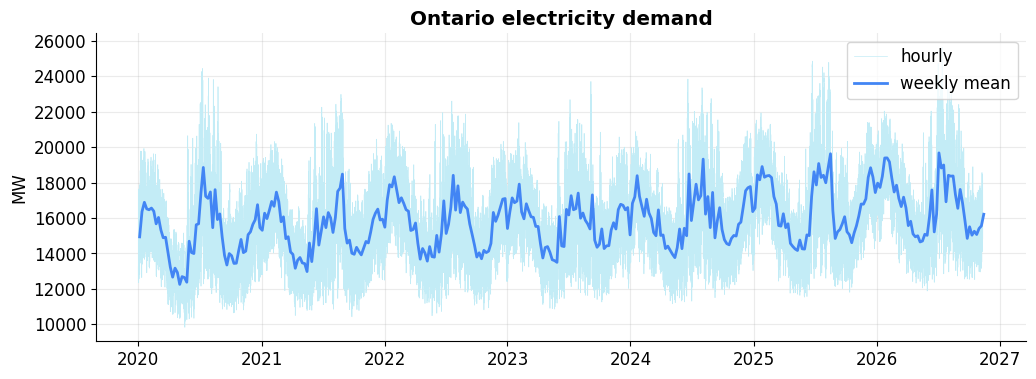

In [ ]:
fig, ax = plt.subplots()
ax.plot(df.index, df["demand"], color=C["band"], lw=0.5, label="hourly")
ax.plot(df["demand"].resample("W").mean(), color=C["lstm"], lw=2, label="weekly mean")
ax.set(title="Ontario electricity demand", ylabel="MW")
ax.legend(loc="upper right")
save(fig, "01_full_series"); plt.show()

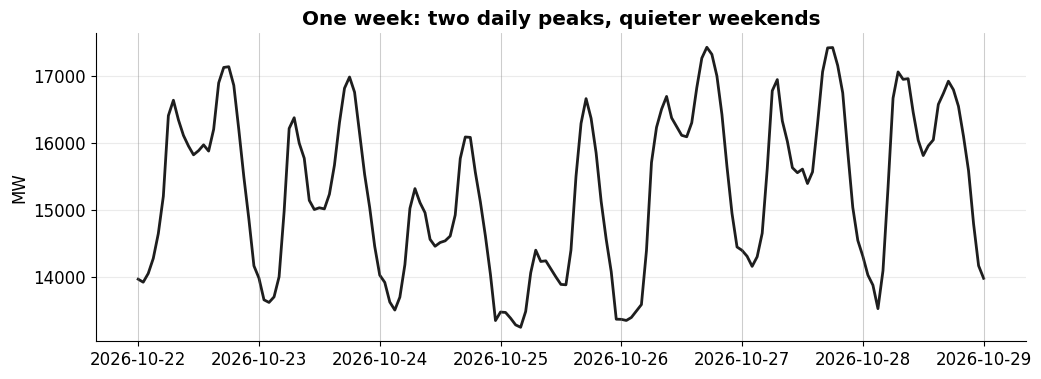

In [ ]:
week = df.loc[df.index.max() - pd.Timedelta(days=21): df.index.max() - pd.Timedelta(days=14), "demand"]
fig, ax = plt.subplots()
ax.plot(week.index, week, color=C["actual"], lw=2)
for d in pd.date_range(week.index.min().normalize(), week.index.max(), freq="D"):
    ax.axvline(d, color="grey", lw=0.5, alpha=0.4)
ax.set(title="One week: two daily peaks, quieter weekends", ylabel="MW")
save(fig, "02_one_week"); plt.show()

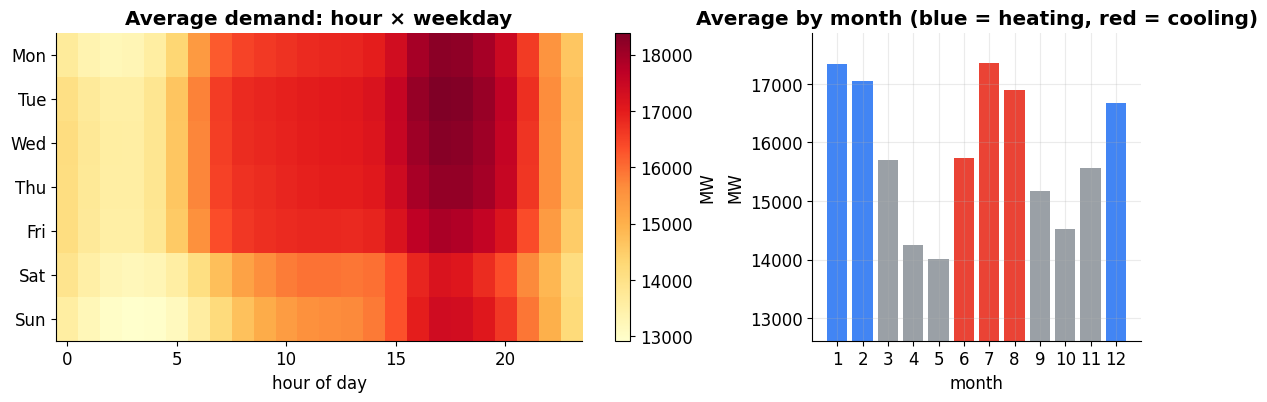

In [ ]:
prof = df.assign(hour=df.index.hour, dow=df.index.day_name().str[:3]).pivot_table(
    index="dow", columns="hour", values="demand", aggfunc="mean")
prof = prof.loc[["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]]
monthly = df["demand"].groupby(df.index.month).mean()

fig, (a1, a2) = plt.subplots(1, 2, figsize=(14, 4), gridspec_kw={"width_ratios": [2, 1]})
im = a1.imshow(prof, aspect="auto", cmap="YlOrRd")
a1.set(yticks=range(7), yticklabels=prof.index, xlabel="hour of day", title="Average demand: hour × weekday")
a1.grid(False); fig.colorbar(im, ax=a1, label="MW")
a2.bar(monthly.index, monthly.values, color=[C["lstm"] if m in (12, 1, 2) else C["qlstm"] if m in (6, 7, 8) else C["naive"] for m in monthly.index])
a2.set(title="Average by month (blue = heating, red = cooling)", xlabel="month", ylabel="MW", xticks=range(1, 13), ylim=(monthly.min() * 0.9, monthly.max() * 1.03))
save(fig, "03_seasonality"); plt.show()

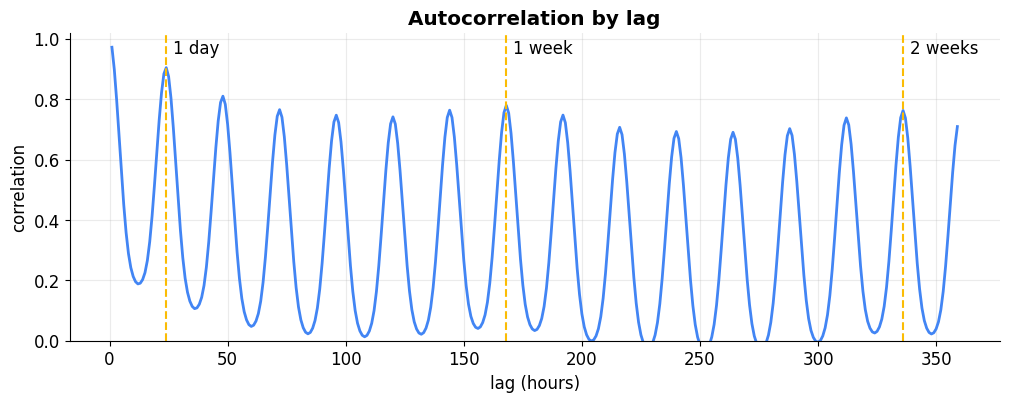

In [ ]:
lags = np.arange(1, 24 * 15)
acf = np.array([df["demand"].autocorr(l) for l in lags])
fig, ax = plt.subplots()
ax.plot(lags, acf, color=C["lstm"], lw=2)
for l, txt in [(24, "1 day"), (168, "1 week"), (336, "2 weeks")]:
    ax.axvline(l, color=C["seasonal"], ls="--"); ax.text(l + 3, 0.95, txt)
ax.set(title="Autocorrelation by lag", xlabel="lag (hours)", ylabel="correlation", ylim=(0, 1.02))
save(fig, "04_autocorrelation"); plt.show()

Daily and weekly cycles (autocorrelation peaks at 24 h and 168 h), plus winter heating and summer cooling peaks: "same hour last week" is a strong baseline.

## 3 · Chronological split
Train until mid-2025, validate on the second half of 2025, test on 2026.

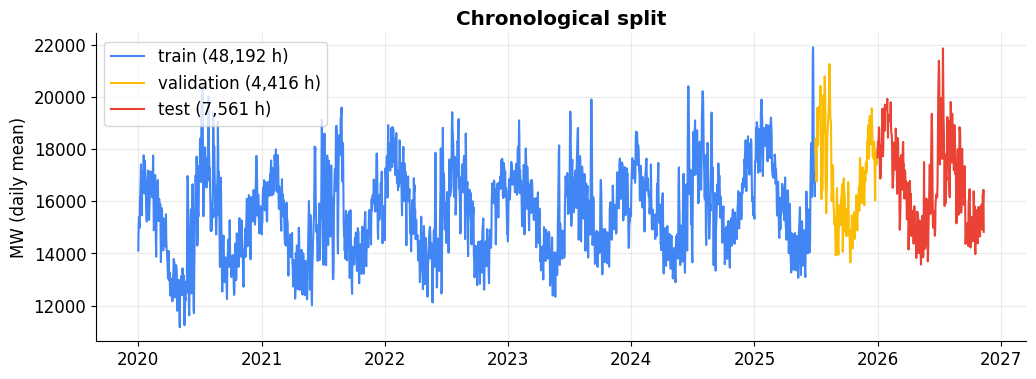

In [ ]:
VAL_START, TEST_START = "2025-07-01", "2026-01-01"

fig, ax = plt.subplots()
for (a, b), col, lab in [((None, VAL_START), C["lstm"], "train"), ((VAL_START, TEST_START), C["seasonal"], "validation"), ((TEST_START, None), C["qlstm"], "test")]:
    part = df.loc[a:b, "demand"]
    part = part[part.index < pd.Timestamp(b)] if b else part
    ax.plot(part.resample("D").mean(), color=col, lw=1.5, label=f"{lab} ({len(part):,} h)")
ax.legend(loc="upper left"); ax.set(title="Chronological split", ylabel="MW (daily mean)")
save(fig, "05_split"); plt.show()

## 4 · Features and sliding windows
Input: the last 168 hours of demand and calendar features. Output: the next 24 hours.

In [ ]:
LOOKBACK, HORIZON = 168, 24

try:
    import holidays
    on_holidays = holidays.Canada(subdiv="ON", years=range(df.index.year.min(), df.index.year.max() + 1))
except Exception:
    on_holidays = {}

feat = pd.DataFrame(index=df.index)
feat["demand"] = df["demand"]
feat["hour_sin"], feat["hour_cos"] = np.sin(2 * np.pi * df.index.hour / 24), np.cos(2 * np.pi * df.index.hour / 24)
feat["dow_sin"], feat["dow_cos"] = np.sin(2 * np.pi * df.index.dayofweek / 7), np.cos(2 * np.pi * df.index.dayofweek / 7)
feat["doy_sin"], feat["doy_cos"] = np.sin(2 * np.pi * df.index.dayofyear / 365.25), np.cos(2 * np.pi * df.index.dayofyear / 365.25)
feat["off_day"] = ((df.index.dayofweek >= 5) | pd.Index(df.index.date).isin(list(on_holidays))).astype(float)

i_val, i_test = feat.index.searchsorted(pd.Timestamp(VAL_START)), feat.index.searchsorted(pd.Timestamp(TEST_START))
mu, sigma = feat["demand"][:i_val].mean(), feat["demand"][:i_val].std()  # train period only
X_all = feat.values.astype("float32").copy()
X_all[:, 0] = (X_all[:, 0] - mu) / sigma
y_all = X_all[:, 0]
y_mw = feat["demand"].values

def windows(starts):
    X = np.stack([X_all[t - LOOKBACK:t] for t in starts])
    Y = np.stack([y_all[t:t + HORIZON] for t in starts])
    return X, Y

hours = feat.index.hour
train_starts = np.arange(LOOKBACK, i_val - HORIZON + 1)
val_starts = np.array([t for t in range(i_val, i_test - HORIZON + 1) if hours[t] == 0])
test_starts = np.array([t for t in range(i_test, len(feat) - HORIZON + 1) if hours[t] == 0])

X_train, Y_train = windows(train_starts)
X_val, Y_val = windows(val_starts)
X_test, Y_test = windows(test_starts)
Y_test_mw = np.stack([y_mw[t:t + HORIZON] for t in test_starts])
print(f"train {X_train.shape} | val {X_val.shape} | test {X_test.shape}  (windows, hours, features)")

train (48001, 168, 8) | val (184, 168, 8) | test (315, 168, 8)  (windows, hours, features)


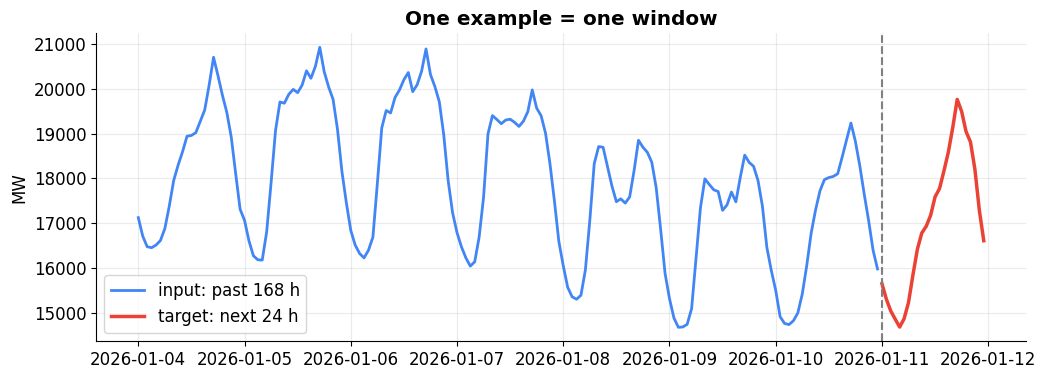

In [ ]:
t0 = test_starts[10]
fig, ax = plt.subplots()
ax.plot(feat.index[t0 - LOOKBACK:t0], y_mw[t0 - LOOKBACK:t0], color=C["lstm"], lw=2, label="input: past 168 h")
ax.plot(feat.index[t0:t0 + HORIZON], y_mw[t0:t0 + HORIZON], color=C["qlstm"], lw=2.5, label="target: next 24 h")
ax.axvline(feat.index[t0], color="grey", ls="--")
ax.legend(); ax.set(title="One example = one window", ylabel="MW")
save(fig, "06_window"); plt.show()

## 5 · Baselines

In [ ]:
def metrics(pred, true=Y_test_mw):
    err = pred - true
    return {"MAE (MW)": np.abs(err).mean(), "RMSE (MW)": np.sqrt((err ** 2).mean()),
            "MAPE (%)": 100 * np.abs(err / true).mean()}

preds = {
    "Naive (last value)": np.stack([np.repeat(y_mw[t - 1], HORIZON) for t in test_starts]),
    "Same hour yesterday": np.stack([y_mw[t - 24:t] for t in test_starts]),
    "Same hour last week": np.stack([y_mw[t - 168:t - 144] for t in test_starts]),
}
pd.DataFrame({k: metrics(v) for k, v in preds.items()}).T.round(1)

,MAE (MW),RMSE (MW),MAPE (%)
Naive (last value),1722.6,2155.3,9.8
Same hour yesterday,810.6,1068.7,4.8
Same hour last week,1150.0,1545.8,6.8


## 6 · Keras models
`TRAIN = False` reloads the saved models.

In [ ]:
TRAIN = True
EPOCHS = 30
N_FEAT = X_train.shape[-1]

def fit(model, name, loss="mae"):
    path = f"models/{name}.keras"
    if not TRAIN and os.path.exists(path):
        return keras.models.load_model(path, compile=False), None
    model.compile(optimizer=keras.optimizers.Adam(1e-3), loss=loss)
    hist = model.fit(X_train, Y_train if loss == "mae" else Y_train[..., None],
                     validation_data=(X_val, Y_val if loss == "mae" else Y_val[..., None]),
                     epochs=EPOCHS, batch_size=256, verbose=2,
                     callbacks=[keras.callbacks.EarlyStopping(patience=4, restore_best_weights=True)])
    model.save(path)
    return model, hist

def to_mw(z):
    return z * sigma + mu

**Linear:** flatten the window, one Dense layer (cf. Zeng et al., AAAI 2023).

In [ ]:
linear = keras.Sequential([keras.Input((LOOKBACK, N_FEAT)), keras.layers.Flatten(), keras.layers.Dense(HORIZON)], name="linear")
linear, h_lin = fit(linear, "linear")
preds["Linear (Keras)"] = to_mw(linear.predict(X_test, verbose=0))

Epoch 1/30
188/188 - 2s - 13ms/step - loss: 0.3261 - val_loss: 0.2482
Epoch 2/30
188/188 - 1s - 3ms/step - loss: 0.2486 - val_loss: 0.2340
Epoch 3/30
188/188 - 1s - 3ms/step - loss: 0.2390 - val_loss: 0.2280
Epoch 4/30
188/188 - 1s - 3ms/step - loss: 0.2343 - val_loss: 0.2262
Epoch 5/30
188/188 - 1s - 4ms/step - loss: 0.2320 - val_loss: 0.2240
Epoch 6/30
188/188 - 1s - 7ms/step - loss: 0.2303 - val_loss: 0.2242
Epoch 7/30
188/188 - 1s - 3ms/step - loss: 0.2292 - val_loss: 0.2221
Epoch 8/30
188/188 - 1s - 4ms/step - loss: 0.2282 - val_loss: 0.2232
Epoch 9/30
188/188 - 1s - 4ms/step - loss: 0.2273 - val_loss: 0.2226
Epoch 10/30
188/188 - 1s - 4ms/step - loss: 0.2267 - val_loss: 0.2214
Epoch 11/30
188/188 - 1s - 6ms/step - loss: 0.2263 - val_loss: 0.2224
Epoch 12/30
188/188 - 1s - 3ms/step - loss: 0.2258 - val_loss: 0.2223
Epoch 13/30
188/188 - 1s - 3ms/step - loss: 0.2254 - val_loss: 0.2215
Epoch 14/30
188/188 - 1s - 3ms/step - loss: 0.2251 - val_loss: 0.2210
Epoch 15/30
188/188 - 1s - 3

**LSTM:** multi-output, the 24 hours are predicted at once.

In [ ]:
lstm = keras.Sequential([
    keras.Input((LOOKBACK, N_FEAT)),
    keras.layers.LSTM(64),
    keras.layers.Dense(64, activation="relu"),
    keras.layers.Dense(HORIZON),
], name="lstm")
lstm.summary()
lstm, h_lstm = fit(lstm, "lstm")
preds["LSTM (Keras)"] = to_mw(lstm.predict(X_test, verbose=0))

Model: "lstm"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 64)             │        18,688 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 24)             │         1,560 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 24,408 (95.34 KB)

 Trainable params: 24,408 (95.34 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/30
188/188 - 5s - 28ms/step - loss: 0.3749 - val_loss: 0.2775
Epoch 2/30
188/188 - 2s - 10ms/step - loss: 0.2370 - val_loss: 0.2550
Epoch 3/30
188/188 - 3s - 14ms/step - loss: 0.2232 - val_loss: 0.2425
Epoch 4/30
188/188 - 2s - 10ms/step - loss: 0.2163 - val_loss: 0.2379
Epoch 5/30
188/188 - 2s - 10ms/step - loss: 0.2116 - val_loss: 0.2348
Epoch 6/30
188/188 - 3s - 15ms/step - loss: 0.2080 - val_loss: 0.2322
Epoch 7/30
188/188 - 4s - 23ms/step - loss: 0.2051 - val_loss: 0.2336
Epoch 8/30
188/188 - 2s - 10ms/step - loss: 0.2026 - val_loss: 0.2341
Epoch 9/30
188/188 - 2s - 10ms/step - loss: 0.2005 - val_loss: 0.2333
Epoch 10/30
188/188 - 2s - 10ms/step - loss: 0.1984 - val_loss: 0.2329


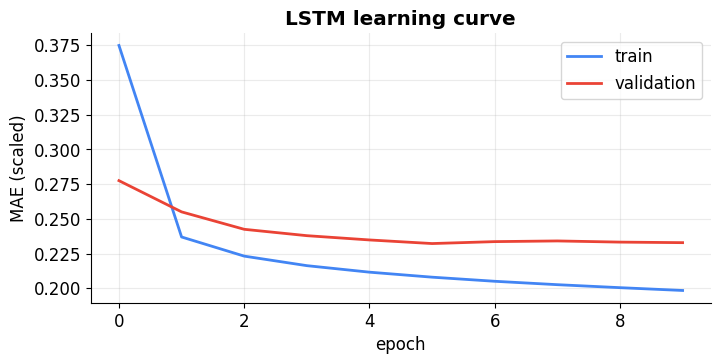

In [ ]:
if h_lstm is not None:
    fig, ax = plt.subplots(figsize=(8, 3.5))
    ax.plot(h_lstm.history["loss"], color=C["lstm"], lw=2, label="train")
    ax.plot(h_lstm.history["val_loss"], color=C["qlstm"], lw=2, label="validation")
    ax.set(title="LSTM learning curve", xlabel="epoch", ylabel="MAE (scaled)"); ax.legend()
    save(fig, "07_learning_curve"); plt.show()

**Quantile LSTM:** same network, P10 / P50 / P90 per hour, pinball loss.

In [ ]:
QUANTILES = tf.constant([0.1, 0.5, 0.9])

def pinball(y_true, y_pred):
    e = y_true - y_pred
    return tf.reduce_mean(tf.maximum(QUANTILES * e, (QUANTILES - 1) * e))

qlstm = keras.Sequential([
    keras.Input((LOOKBACK, N_FEAT)),
    keras.layers.LSTM(64),
    keras.layers.Dense(64, activation="relu"),
    keras.layers.Dense(HORIZON * 3),
    keras.layers.Reshape((HORIZON, 3)),
], name="quantile_lstm")
qlstm, _ = fit(qlstm, "quantile_lstm", loss=pinball)
q_test = to_mw(np.sort(qlstm.predict(X_test, verbose=0), axis=-1))
preds["Quantile LSTM (P50)"] = q_test[..., 1]

Epoch 1/30
188/188 - 5s - 27ms/step - loss: 0.1597 - val_loss: 0.0887
Epoch 2/30
188/188 - 2s - 11ms/step - loss: 0.0796 - val_loss: 0.0792
Epoch 3/30
188/188 - 2s - 10ms/step - loss: 0.0734 - val_loss: 0.0773
Epoch 4/30
188/188 - 2s - 11ms/step - loss: 0.0705 - val_loss: 0.0745
Epoch 5/30
188/188 - 3s - 14ms/step - loss: 0.0686 - val_loss: 0.0729
Epoch 6/30
188/188 - 2s - 10ms/step - loss: 0.0671 - val_loss: 0.0723
Epoch 7/30
188/188 - 2s - 10ms/step - loss: 0.0660 - val_loss: 0.0716
Epoch 8/30
188/188 - 2s - 11ms/step - loss: 0.0651 - val_loss: 0.0714
Epoch 9/30
188/188 - 2s - 10ms/step - loss: 0.0643 - val_loss: 0.0711
Epoch 10/30
188/188 - 2s - 11ms/step - loss: 0.0637 - val_loss: 0.0711
Epoch 11/30
188/188 - 3s - 17ms/step - loss: 0.0631 - val_loss: 0.0711
Epoch 12/30
188/188 - 2s - 10ms/step - loss: 0.0626 - val_loss: 0.0714
Epoch 13/30
188/188 - 2s - 10ms/step - loss: 0.0622 - val_loss: 0.0718
Epoch 14/30
188/188 - 2s - 10ms/step - loss: 0.0618 - val_loss: 0.0723


## 7 · TimesFM (zero-shot)
Pretrained Google foundation model, no training on our data. TimesFM 2.5 weights are Apache-2.0; TimesFM 3.0 weights are non-commercial / non-production (see the [README](https://github.com/google-research/timesfm)).

In [ ]:
RUN_TIMESFM = True
if RUN_TIMESFM:
    !pip -q install "timesfm[torch] @ git+https://github.com/google-research/timesfm.git"

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [ ]:
tfm_q = None
if RUN_TIMESFM:
    try:
        import torch, timesfm
        torch.set_float32_matmul_precision("high")
        tfm = timesfm.TimesFM_2p5_200M_torch.from_pretrained("google/timesfm-2.5-200m-pytorch")
        tfm.compile(timesfm.ForecastConfig(max_context=1024, max_horizon=256, normalize_inputs=True,
                                           use_continuous_quantile_head=True, fix_quantile_crossing=True))
        contexts = [y_mw[t - 1024:t] for t in test_starts]
        point, quant = tfm.forecast(horizon=HORIZON, inputs=contexts)
        quant = np.asarray(quant)[:, :HORIZON]
        preds["TimesFM (zero-shot)"] = np.asarray(point)[:, :HORIZON]
        tfm_q = np.stack([quant[..., 1], quant[..., 5], quant[..., 9]], axis=-1)  # P10, P50, P90
    except Exception as e:
        print("TimesFM skipped:", e)

config.json:   0%|          | 0.00/475 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  925MB            

model.safetensors: downloading bytes:           |  0.00B            

## 8 · Results

In [ ]:
colors = {"Naive (last value)": C["naive"], "Same hour yesterday": C["seasonal"], "Same hour last week": C["seasonal"],
          "Linear (Keras)": C["linear"], "LSTM (Keras)": C["lstm"], "Quantile LSTM (P50)": C["qlstm"], "TimesFM (zero-shot)": C["timesfm"]}

results = pd.DataFrame({k: metrics(v) for k, v in preds.items()}).T.sort_values("MAE (MW)")
ref = results.loc["Same hour last week", "MAE (MW)"]
results["vs last week (%)"] = 100 * (ref - results["MAE (MW)"]) / ref
results.round(1).to_csv("artifacts/results.csv")
results.round(1)

,MAE (MW),RMSE (MW),MAPE (%),vs last week (%)
Quantile LSTM (P50),530.4,728.5,3.1,53.9
Linear (Keras),549.8,767.9,3.2,52.2
LSTM (Keras),557.7,744.0,3.3,51.5
TimesFM (zero-shot),585.6,839.9,3.4,49.1
Same hour yesterday,810.6,1068.7,4.8,29.5
Same hour last week,1150.0,1545.8,6.8,0.0
Naive (last value),1722.6,2155.3,9.8,-49.8


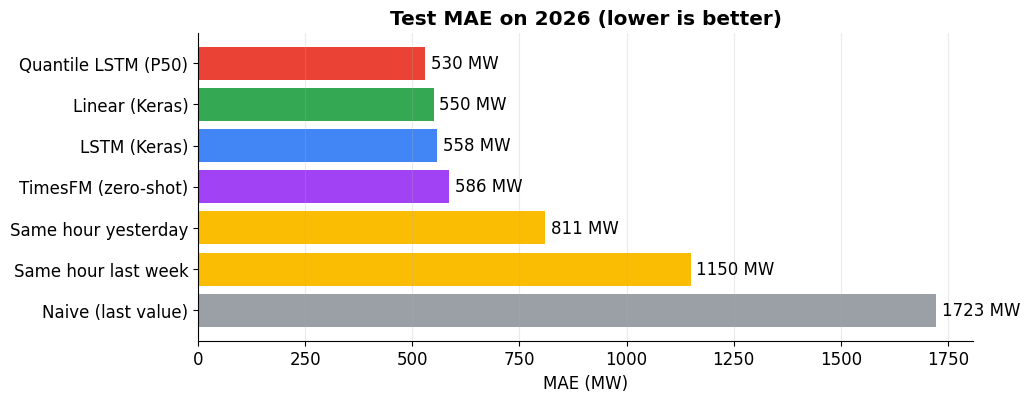

In [ ]:
r = results["MAE (MW)"].sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(10, 4))
bars = ax.barh(r.index, r.values, color=[colors.get(k, "grey") for k in r.index])
ax.bar_label(bars, fmt="%.0f MW", padding=4)
ax.set(title="Test MAE on 2026 (lower is better)", xlabel="MAE (MW)"); ax.grid(axis="y", alpha=0)
save(fig, "08_scoreboard"); plt.show()

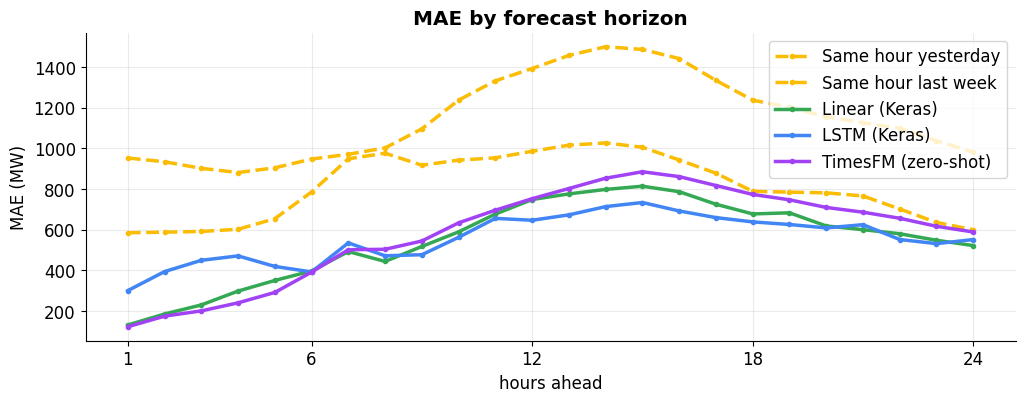

In [ ]:
fig, ax = plt.subplots()
for k in ["Same hour yesterday", "Same hour last week", "Linear (Keras)", "LSTM (Keras)", "TimesFM (zero-shot)"]:
    if k in preds:
        ax.plot(range(1, HORIZON + 1), np.abs(preds[k] - Y_test_mw).mean(0), lw=2.5, color=colors[k],
                ls="--" if "Same" in k else "-", label=k, marker="o", ms=3)
ax.set(title="MAE by forecast horizon", xlabel="hours ahead", ylabel="MAE (MW)", xticks=[1, 6, 12, 18, 24]); ax.legend()
save(fig, "09_mae_by_horizon"); plt.show()

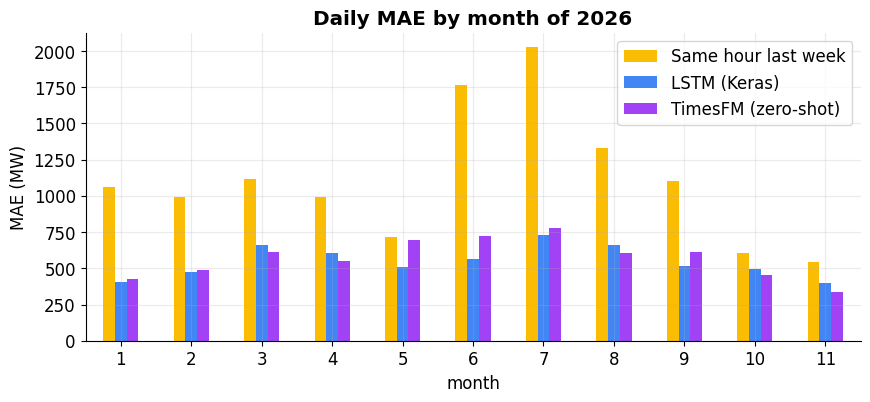

Hardest days for the LSTM: ['Sun 14 Jun', 'Fri 03 Apr', 'Wed 15 Jul']


In [ ]:
months = feat.index[test_starts].month
cmp = [k for k in ["Same hour last week", "LSTM (Keras)", "TimesFM (zero-shot)"] if k in preds]
err = pd.DataFrame({k: np.abs(preds[k] - Y_test_mw).mean(1) for k in cmp}).groupby(months).mean()
ax = err.plot.bar(color=[colors[k] for k in cmp], figsize=(10, 4), rot=0)
ax.set(title="Daily MAE by month of 2026", xlabel="month", ylabel="MAE (MW)")
save(ax.figure, "11_error_by_month"); plt.show()

worst = np.argsort(np.abs(preds["LSTM (Keras)"] - Y_test_mw).mean(1))[-3:][::-1]
print("Hardest days for the LSTM:", [f"{feat.index[test_starts[i]]:%a %d %b}" for i in worst])

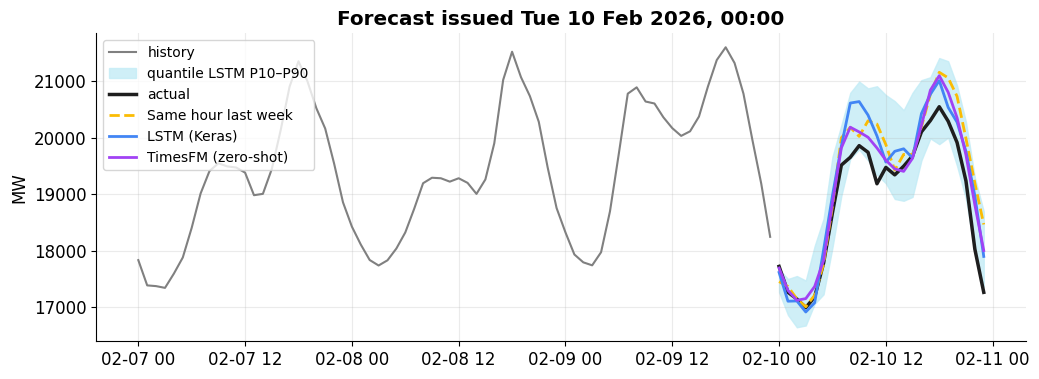

In [ ]:
DAY = 40  # @param {type:"slider", min:0, max:300, step:1}
d = min(DAY, len(test_starts) - 1)
t = test_starts[d]
ctx, fut = feat.index[t - 72:t], feat.index[t:t + HORIZON]
fig, ax = plt.subplots()
ax.plot(ctx, y_mw[t - 72:t], color="grey", lw=1.5, label="history")
ax.fill_between(fut, q_test[d, :, 0], q_test[d, :, 2], color=C["band"], alpha=0.8, label="quantile LSTM P10–P90")
ax.plot(fut, Y_test_mw[d], color=C["actual"], lw=2.5, label="actual")
for k in ["Same hour last week", "LSTM (Keras)", "TimesFM (zero-shot)"]:
    if k in preds:
        ax.plot(fut, preds[k][d], color=colors[k], lw=2, ls="--" if "Same" in k else "-", label=k)
ax.set(title=f"Forecast issued {feat.index[t]:%a %d %b %Y}, 00:00", ylabel="MW"); ax.legend(loc="upper left", fontsize=10)
save(fig, f"10_day_{d}"); plt.show()

## 9 · Uncertainty: interval coverage
A nominal 80 % interval (P10–P90) should contain the actual value about 80 % of the time.

               coverage (%)  mean width (MW)
Quantile LSTM          72.8           1534.5
TimesFM                76.3           1699.1


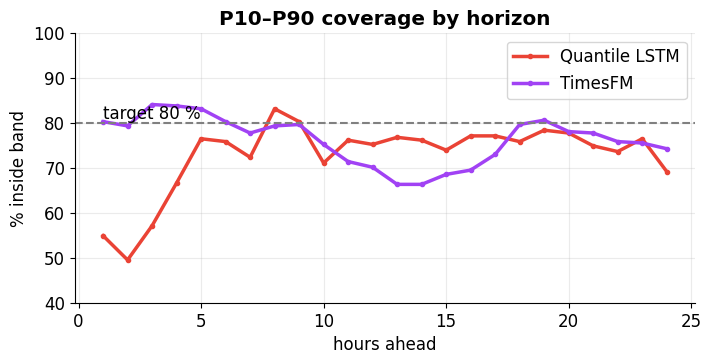

In [ ]:
bands = {"Quantile LSTM": q_test}
if tfm_q is not None:
    bands["TimesFM"] = tfm_q
cov = pd.DataFrame({name: {"coverage (%)": 100 * ((Y_test_mw >= q[..., 0]) & (Y_test_mw <= q[..., 2])).mean(),
                           "mean width (MW)": (q[..., 2] - q[..., 0]).mean()} for name, q in bands.items()}).T
cov.round(1).to_csv("artifacts/coverage.csv")
print(cov.round(1))

fig, ax = plt.subplots(figsize=(8, 3.5))
for name, q in bands.items():
    inside = (Y_test_mw >= q[..., 0]) & (Y_test_mw <= q[..., 2])
    ax.plot(range(1, HORIZON + 1), 100 * inside.mean(0), lw=2.5, marker="o", ms=3,
            color=C["qlstm"] if name == "Quantile LSTM" else C["timesfm"], label=name)
ax.axhline(80, color="grey", ls="--"); ax.text(1, 81, "target 80 %")
ax.set(title="P10–P90 coverage by horizon", xlabel="hours ahead", ylabel="% inside band", ylim=(40, 100)); ax.legend()
save(fig, "12_coverage"); plt.show()

## 10 · Leakage check: shuffled vs chronological split
Same small network, trained once on randomly shuffled windows and once on the chronological split.

In [ ]:
all_starts = np.arange(LOOKBACK, len(feat) - HORIZON + 1, 3)
shuffled = np.random.default_rng(SEED).permutation(all_starts)
cut = int(0.85 * len(shuffled))
Xs_tr, Ys_tr = windows(shuffled[:cut])
Xs_te, Ys_te = windows(shuffled[cut:])

leaky = keras.Sequential([keras.Input((LOOKBACK, N_FEAT)), keras.layers.Flatten(),
                          keras.layers.Dense(256, activation="relu"), keras.layers.Dense(HORIZON)])
leaky.compile("adam", "mae")
leaky.fit(Xs_tr, Ys_tr, epochs=10, batch_size=256, verbose=0)
honest = keras.models.clone_model(leaky); honest.compile("adam", "mae")
honest.fit(X_train, Y_train, epochs=10, batch_size=256, verbose=0)

leak = pd.Series({"Shuffled split": np.abs(to_mw(leaky.predict(Xs_te, verbose=0)) - to_mw(Ys_te)).mean(),
                  "Chronological split (2026)": np.abs(to_mw(honest.predict(X_test, verbose=0)) - Y_test_mw).mean()},
                 name="MAE (MW)")
leak.round(1).to_csv("artifacts/leakage.csv")
leak.round(1)

,MAE (MW)
Shuffled split,532.5
Chronological split (2026),565.1


## 11 · Save artifacts (you can use them later)

In [ ]:
np.savez_compressed(
    "artifacts/predictions.npz",
    test_times=feat.index[test_starts].values.astype("datetime64[h]"),
    y_true=Y_test_mw, q_lstm=q_test,
    q_timesfm=tfm_q if tfm_q is not None else np.empty(0),
    names=np.array(list(preds)), preds=np.stack([preds[k] for k in preds]),
    mu=mu, sigma=sigma, lookback=LOOKBACK, horizon=HORIZON,
)
import shutil
for name in ["linear", "lstm", "quantile_lstm"]:
    if os.path.exists(f"models/{name}.keras"):
        shutil.copy(f"models/{name}.keras", f"artifacts/{name}.keras")
!zip -qr devfest_outputs.zip artifacts figures
print(sorted(os.listdir("artifacts")))
try:
    from google.colab import files
    files.download("devfest_outputs.zip")
except ImportError:
    pass

['coverage.csv', 'leakage.csv', 'linear.keras', 'lstm.keras', 'ontario_demand.csv', 'predictions.npz', 'quantile_lstm.keras', 'results.csv']


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>